Step 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


Step 2 — Load the CEAS_08 dataset

In [2]:
ceas_path = r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Text_Phishing_Project\text_dataset\CEAS_08.csv"

ceas = pd.read_csv(ceas_path)

print("Dataset loaded successfully!")
print("Shape:", ceas.shape)

Dataset loaded successfully!
Shape: (39154, 7)


Step 3 — Inspect the columns

In [3]:
print("Columns:")
print(ceas.columns.tolist())

print("\nFirst 5 rows:")
display(ceas.head())

Columns:
['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']

First 5 rows:


,sender,receiver,date,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


Step 4 — Check the labels

In [4]:
print("Label counts:")
print(ceas["label"].value_counts(dropna=False))

print("\nLabel percentages:")
print(ceas["label"].value_counts(normalize=True, dropna=False) * 100)

Label counts:
label
1    21842
0    17312
Name: count, dtype: int64

Label percentages:
label
1    55.78485
0    44.21515
Name: proportion, dtype: float64


Step 5 — Inspect examples from each label

In [5]:
print("Examples with label 0:")
display(ceas[ceas["label"] == 0][["subject", "body", "label"]].head(3))

print("\nExamples with label 1:")
display(ceas[ceas["label"] == 1][["subject", "body", "label"]].head(3))

Examples with label 0:


,subject,body,label
3,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0
8,[Bug 5780] URI processing turns uuencoded stri...,http://issues.apache.org/SpamAssassin/show_bug...,0
15,RE: Trial IRC Certificate Application,"\nPlelim,\n\nJust to remind you that if a cert...",0



Examples with label 1:


,subject,body,label
0,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1
1,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1
2,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1


Step 6 — Check whether we have enough data for 1:3

Before we decide the final size, let's check missing/empty email bodies, because text classification needs usable text.

In [6]:
print("Missing values:")
print(ceas[["subject", "body", "label"]].isnull().sum())

print("\nEmpty subjects:")
print((ceas["subject"].fillna("").str.strip() == "").sum())

print("\nEmpty bodies:")
print((ceas["body"].fillna("").str.strip() == "").sum())

Missing values:
subject    28
body        0
label       0
dtype: int64

Empty subjects:
28

Empty bodies:
0


Step 7 — Create our 1:3 dataset
This gives us exactly 1 : 3.
We will copy/sample the records; we will NOT modify CEAS_08.csv.

In [7]:
# Create a 1:3 dataset without modifying the original CEAS_08 dataset

SEED = 42

legitimate = ceas[ceas["label"] == 0].sample(
    n=5000,
    random_state=SEED
)

phishing = ceas[ceas["label"] == 1].sample(
    n=15000,
    random_state=SEED
)

text_dataset = pd.concat(
    [legitimate, phishing],
    ignore_index=True
)

# Shuffle the combined dataset
text_dataset = text_dataset.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("1:3 dataset created successfully!")
print("Total:", len(text_dataset))
print("\nLabel counts:")
print(text_dataset["label"].value_counts())

1:3 dataset created successfully!
Total: 20000

Label counts:
label
1    15000
0     5000
Name: count, dtype: int64


Step 8 — Save our 1:3 dataset

In [8]:
output_path = r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Text_Phishing_Project\text_dataset\FINAL_TEXT_DATASET_1_3.csv"

text_dataset.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("Location:")
print(output_path)

Dataset saved successfully!
Location:
E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Text_Phishing_Project\text_dataset\FINAL_TEXT_DATASET_1_3.csv


Step 9 — Create Train / Validation / Test splits

This is important because we want our test set separated before model training.

We'll use:

70% Training → 14,000 emails
15% Validation → 3,000 emails
15% Test → 3,000 emails

And we'll keep the 1:3 ratio in each split.

In [9]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    text_dataset,
    test_size=0.30,
    random_state=42,
    stratify=text_dataset["label"]
)

# Second split: divide the temporary 30% into
# 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

print("\nTraining labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())

Training set: (14000, 7)
Validation set: (3000, 7)
Test set: (3000, 7)

Training labels:
label
1    10500
0     3500
Name: count, dtype: int64

Validation labels:
label
1    2250
0     750
Name: count, dtype: int64

Test labels:
label
1    2250
0     750
Name: count, dtype: int64


Step 10 — Create the text used by the model

In [10]:
# Combine subject and body into one text field

def combine_text(df):
    subject = df["subject"].fillna("").astype(str)
    body = df["body"].fillna("").astype(str)

    return subject + " " + body


X_train = combine_text(train_df)
X_val = combine_text(val_df)
X_test = combine_text(test_df)

y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]

print("Text preparation completed!")

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nExample text:")
print(X_train.iloc[0][:500])

Text preparation completed!

Training samples: 14000
Validation samples: 3000
Test samples: 3000

Example text:
Luxurious costume replica watches at lowest prices  
Best IWC replica watches at Replica Classics

Qualitative replica watches for most exacting people   

Ladies and Gents watches from only 9.99 inc. delivery ...   

http://lyingsopnag.com/





Step 11 — Convert text into numerical features

A machine-learning model can't directly understand raw sentences like:

"Luxurious costume replica watches at lowest prices..."

So we'll use TF-IDF.

TF-IDF converts important words/phrases into numerical values based on how useful they are for distinguishing legitimate and phishing emails.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed!")

print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training shape: (14000, 20000)
Validation shape: (3000, 20000)
Test shape: (3000, 20000)


Step 12 — Train Logistic Regression

In [12]:
from sklearn.linear_model import LogisticRegression

# Create the model
text_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
text_model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


Step 13 — Evaluate on the validation set

In [13]:
from sklearn.metrics import accuracy_score

val_predictions = text_model.predict(X_val_tfidf)

val_accuracy = accuracy_score(y_val, val_predictions)

print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Validation Accuracy: 99.17%


Step 14 — Classification Report

In [14]:
from sklearn.metrics import classification_report

print("Validation Classification Report:\n")

print(
    classification_report(
        y_val,
        val_predictions,
        target_names=["LEGITIMATE", "PHISHING"]
    )
)

Validation Classification Report:

              precision    recall  f1-score   support

  LEGITIMATE       0.99      0.97      0.98       750
    PHISHING       0.99      1.00      0.99      2250

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000



Step 15 — Evaluate on the unseen test set

In [15]:
from sklearn.metrics import accuracy_score

test_predictions = text_model.predict(X_test_tfidf)

test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 99.33%


Step 16 — Test Classification Report

In [16]:
from sklearn.metrics import classification_report

print("Test Classification Report:\n")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["LEGITIMATE", "PHISHING"]
    )
)

Test Classification Report:

              precision    recall  f1-score   support

  LEGITIMATE       0.99      0.98      0.99       750
    PHISHING       0.99      1.00      1.00      2250

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000



Step 17 — Create the Confusion Matrix

Confusion Matrix:
[[ 737   13]
 [   7 2243]]


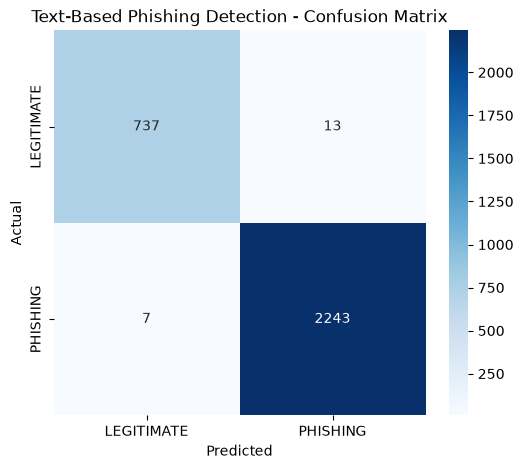

In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, test_predictions)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["LEGITIMATE", "PHISHING"],
    yticklabels=["LEGITIMATE", "PHISHING"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Text-Based Phishing Detection - Confusion Matrix")
plt.show()

Step 18 — Save the trained model

In [18]:
import os
import joblib

models_path = r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Text_Phishing_Project\models"

os.makedirs(models_path, exist_ok=True)

# Save Logistic Regression model
joblib.dump(
    text_model,
    os.path.join(models_path, "text_phishing_logistic_regression.pkl")
)

# Save TF-IDF vectorizer
joblib.dump(
    vectorizer,
    os.path.join(models_path, "text_phishing_tfidf_vectorizer.pkl")
)

print("Model and TF-IDF vectorizer saved successfully!")
print("\nSaved files:")
print("1. text_phishing_logistic_regression.pkl")
print("2. text_phishing_tfidf_vectorizer.pkl")

Model and TF-IDF vectorizer saved successfully!

Saved files:
1. text_phishing_logistic_regression.pkl
2. text_phishing_tfidf_vectorizer.pkl


Step 19 — Create the Text Scanner

In [19]:
def predict_text(message):
    # Convert the input text into TF-IDF features
    message_tfidf = vectorizer.transform([message])

    # Get prediction
    prediction = text_model.predict(message_tfidf)[0]

    # Get probability
    probabilities = text_model.predict_proba(message_tfidf)[0]

    # Probability of the predicted class
    confidence = probabilities[prediction] * 100

    if prediction == 1:
        result = "PHISHING"
    else:
        result = "LEGITIMATE"

    return result, confidence

Step 20 — Create the Text Scanner UI

Now we'll create a box where you can paste any email/message and click SCAN.

Step 20A — Restore predict_text()

In [20]:
def predict_text(message):
    # Convert message into TF-IDF features
    message_tfidf = vectorizer.transform([message])

    # Predict class
    prediction = text_model.predict(message_tfidf)[0]

    # Get prediction probabilities
    probabilities = text_model.predict_proba(message_tfidf)[0]

    # Confidence of predicted class
    confidence = probabilities[prediction] * 100

    # Convert numeric label to class name
    result = "PHISHING" if prediction == 1 else "LEGITIMATE"

    return result, confidence

print("predict_text() restored successfully!")

predict_text() restored successfully!


Step 21 — Connect the SCAN button to the model

Now we'll make the button actually analyze whatever text you paste.

Permanent solution — replace your scanner cells with this one cell

In [21]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Create fresh UI components
message_box = widgets.Textarea(
    placeholder="Paste the email or message here...",
    description="Message:",
    layout=widgets.Layout(width="95%", height="200px")
)

scan_button = widgets.Button(
    description="SCAN",
    button_style="primary",
    layout=widgets.Layout(width="150px")
)

output = widgets.Output()


# 2. Define the scan function
def scan_message(button):
    with output:
        clear_output(wait=True)

        message = message_box.value.strip()

        if not message:
            print("⚠️ Please enter a message to scan.")
            return

        try:
            result, confidence = predict_text(message)

            print("=" * 45)
            print("       TEXT PHISHING DETECTION")
            print("=" * 45)
            print(f"\nPrediction : {result}")
            print(f"Confidence : {confidence:.2f}%")
            print("\n" + "=" * 45)

        except Exception as error:
            print("❌ Error:", type(error).__name__, "-", error)


# 3. Connect the button
scan_button.on_click(scan_message)

# 4. Display the interface
display(message_box)
display(scan_button)
display(output)

print("Text phishing scanner is ready!")

Textarea(value='', description='Message:', layout=Layout(height='200px', width='95%'), placeholder='Paste the …

Button(button_style='primary', description='SCAN', layout=Layout(width='150px'), style=ButtonStyle())

Output()

Text phishing scanner is ready!


Step 22 — Random Test Email button

Step 22A — Recreate test_df

In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the saved 1:3 dataset
text_dataset_path = r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Text_Phishing_Project\text_dataset\FINAL_TEXT_DATASET_1_3.csv"

text_dataset = pd.read_csv(text_dataset_path)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    text_dataset,
    test_size=0.30,
    random_state=42,
    stratify=text_dataset["label"]
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Test dataset recreated successfully!")
print("Test shape:", test_df.shape)
print("\nTest label counts:")
print(test_df["label"].value_counts())

Test dataset recreated successfully!
Test shape: (3000, 7)

Test label counts:
label
1    2250
0     750
Name: count, dtype: int64


In [23]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output

random_button = widgets.Button(
    description="RANDOM TEST EMAIL",
    button_style="info",
    layout=widgets.Layout(width="200px")
)

random_output = widgets.Output()


def show_random_test_email(button):
    with random_output:
        clear_output()

        # Randomly choose a class: 0 = legitimate, 1 = phishing
        selected_label = np.random.choice([0, 1])

        # Select a random email from that class
        class_data = test_df[test_df["label"] == selected_label]
        sample = class_data.sample(1)

        actual_label = sample["label"].iloc[0]
        subject = sample["subject"].iloc[0]
        body = sample["body"].iloc[0]

        actual_class = "PHISHING" if actual_label == 1 else "LEGITIMATE"

        print("=" * 60)
        print("              RANDOM TEST EMAIL")
        print("=" * 60)

        print(f"\nActual Label : {actual_class}")

        print("\nSubject:")
        print(subject if subject.strip() else "(No subject)")

        print("\nMessage:")
        print(body)

        print("\n" + "=" * 60)


random_button.on_click(show_random_test_email)

display(random_button)
display(random_output)

Button(button_style='info', description='RANDOM TEST EMAIL', layout=Layout(width='200px'), style=ButtonStyle()…

Output()

Results file in Jupyter Notebook

In [24]:

from pathlib import Path

# Save the results in your local project folder
results_folder = Path(
    r"E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1"
    r"\Major-Minor_Projectz\Text_Phishing_Project\results"
)

results_folder.mkdir(parents=True, exist_ok=True)

results_text = """
TEXT-BASED PHISHING DETECTION PROJECT
====================================

Dataset:
CEAS_08-derived sampled dataset

Total sampled records:
20,000

Legitimate messages:
5,000

Phishing/spam-type messages:
15,000

Model:
Logistic Regression

Text Feature Extraction:
TF-IDF

TF-IDF Maximum Features:
20,000

N-gram Range:
(1, 2)

Training Records:
14,000

Validation Records:
3,000

Held-out Test Records:
3,000

Validation Accuracy:
99.17%

Held-out Test Accuracy:
99.33%

Test Confusion Matrix:
[[737, 13],
 [7, 2243]]

Class Labels:
0 = Legitimate
1 = Phishing/spam-type

Important Note:
These results were obtained using a sampled dataset
derived from CEAS_08. They should not be interpreted
as guaranteed real-world detection performance.
"""

results_file = results_folder / "final_project_results.txt"
results_file.write_text(results_text.strip() + "\n", encoding="utf-8")

print("Results file created successfully!")
print("Saved to:", results_file)
print("File size:", results_file.stat().st_size, "bytes")


Results file created successfully!
Saved to: E:\yash\VU ALL ASSIGNMENTS & DOCUMENTS\4th year Sem 1\Major-Minor_Projectz\Text_Phishing_Project\results\final_project_results.txt
File size: 798 bytes
